# 04 — E3: refusal threshold and answer quality (owner: J)

**Questions.** (1) Does the top-1 retrieval cosine separate answerable from unanswerable questions, and which
threshold τ should the system use to refuse? (2) How does the number of documents k given to the LLM change
answer quality?

**Setting.** FiQA **dev** only. Unanswerable set: 50 dev questions whose labelled docs were removed from the
corpus (116 docs); J and H checked them by hand and kept **10** that really are unanswerable (40 DROP).
τ grid 0.30–0.90, step 0.01; pick max balanced accuracy = (answer rate + correct-refusal rate) / 2, ties →
smaller τ. Answer quality: 20 answerable questions × k ∈ {1, 3, 5, 10}, `openai/gpt-oss-120b`, scored 1–3 by
J and H together (`wiki/experiments/e3_rubric.md`).

**Outputs.** `report/figures/e3_*.pdf` and `report/tables/e3_*.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().parent                      # run this notebook from notebooks/
sys.path.insert(0, str(REPO / "src"))
from finsight.report import AQUA, BLUE, INK_2, ORANGE, apply_style, save_figure, save_table

apply_style()
RESULTS = REPO / "experiments" / "results"
load = lambda p: json.loads((RESULTS / p).read_text())

scores = load("e3_unanswerable/top_scores.json")["queries"]       # qid -> {top1, group}
curve_a = load("e3_tau_config_a/tau_curve.json")                  # config A (384-d exact)
curve_b = load("e3_tau_config_b/tau_curve.json")                  # config B (128-d PCA + IVF 16)
quality = load("run_e3_gen_001/analysis.json")["quality_by_k"]
verified = set(load("e3_unanswerable/tau_curve.json")["verified_qids"])   # the 10 J+H kept

ans = np.array([v["top1"] for v in scores.values() if v["group"] == "answerable"])
unans = np.array([v["top1"] for q, v in scores.items() if q in verified])
len(ans), len(unans), curve_a["best_balanced"], curve_b["best_balanced"]

(450,
 10,
 {'tau': 0.6,
  'answer_rate': 0.76,
  'correct_refusal_rate': 0.8,
  'balanced': 0.78},
 {'tau': 0.66,
  'answer_rate': 0.6088888888888889,
  'correct_refusal_rate': 0.9,
  'balanced': 0.7544})

## 1. Top-1 cosine: answerable vs. unanswerable (config A)

Each dev question is searched once; we keep only the score of the best document. Unanswerable questions
score lower on average, but the two groups overlap — no τ separates them perfectly.

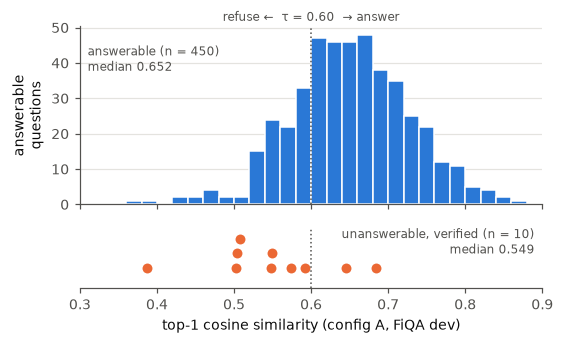

In [2]:
TAU_A = curve_a["best_balanced"]["tau"]
fig, (top, bot) = plt.subplots(2, 1, figsize=(5.2, 3.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

bins = np.arange(0.30, 0.91, 0.02)
top.hist(ans, bins=bins, color=BLUE, edgecolor="white", linewidth=1)
top.set_ylabel("answerable\nquestions")
top.text(0.31, top.get_ylim()[1] * 0.75, f"answerable (n = {len(ans)})\nmedian {np.median(ans):.3f}",
         color=INK_2, fontsize=8)

xs, y = np.sort(unans), []                     # put each dot in the lowest free row: no dot hides another
for i, x in enumerate(xs):
    row = 0
    while any(abs(x - xs[j]) < 0.01 and y[j] == row * 0.45 for j in range(i)):
        row += 1
    y.append(row * 0.45)
bot.plot(xs, y, "o", color=ORANGE, markeredgecolor="white", markeredgewidth=1.5,
         markersize=8)
bot.set_yticks([])
bot.set_ylim(-0.6, 1.2)
bot.grid(False)
bot.spines["left"].set_visible(False)
bot.text(0.89, 0.45, f"unanswerable, verified (n = {len(unans)})\nmedian {np.median(unans):.3f}", ha="right",
         color=INK_2, fontsize=8)

for ax in (top, bot):
    ax.axvline(TAU_A, color=INK_2, linewidth=1, linestyle=":")
top.text(TAU_A, top.get_ylim()[1] * 1.03, f"refuse ←  τ = {TAU_A:.2f}  → answer", color=INK_2, fontsize=8,
         ha="center")
bot.set_xlim(0.30, 0.90)
bot.set_xticks(np.arange(0.3, 0.91, 0.1))
bot.set_xlabel("top-1 cosine similarity (config A, FiQA dev)")
fig.tight_layout()
save_figure(fig, "e3_top1_distribution",
            "Top-1 retrieval cosine on FiQA dev (config A). Top: 450 answerable questions. Bottom: the 10 "
            "manually verified unanswerable questions. The dotted line is the chosen refusal threshold τ = 0.60; "
            f"AUC = {curve_a['auc_verified']:.3f}.")
plt.show()

## 2. Choosing τ by grid search (configs A and B)

For each τ: answer rate = share of the 450 answerable questions with top-1 ≥ τ; correct-refusal rate = share
of the 10 unanswerable with top-1 < τ. We pick the τ with the highest balanced accuracy (their mean), not
plain accuracy: with 450 vs. 10, "always answer" would score 97.8% accuracy but only 0.5 balanced.
B needs its own τ because PCA raises all cosines (medians +0.03).

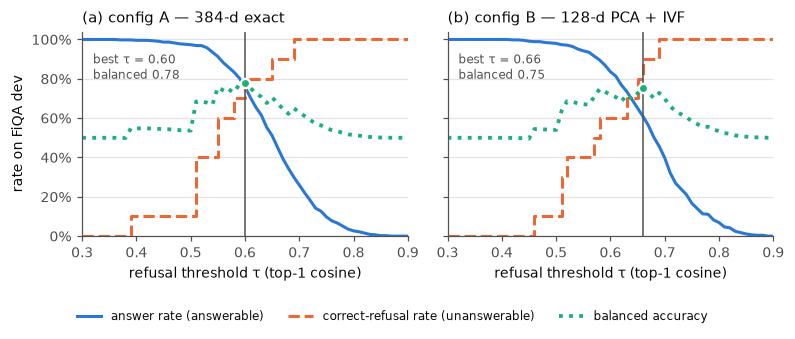

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
for ax, cur, title in [(axes[0], curve_a, "(a) config A — 384-d exact"), (axes[1], curve_b, "(b) config B — 128-d PCA + IVF")]:
    t = [c["tau"] for c in cur["curve"]]
    ax.plot(t, [c["answer_rate"] for c in cur["curve"]], "-", color=BLUE, label="answer rate (answerable)")
    ax.step(t, [c["correct_refusal_rate"] for c in cur["curve"]], "--", where="post", color=ORANGE,
            label="correct-refusal rate (unanswerable)")
    ax.plot(t, [c["balanced"] for c in cur["curve"]], ":", color=AQUA, linewidth=2.5, label="balanced accuracy")
    best = cur["best_balanced"]
    ax.axvline(best["tau"], color=INK_2, linewidth=1)
    ax.plot(best["tau"], best["balanced"], "o", color=AQUA, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
    ax.text(0.32, 0.80, f"best τ = {best['tau']:.2f}\nbalanced {best['balanced']:.2f}", color=INK_2, fontsize=8)
    ax.set_xlim(0.30, 0.90)
    ax.set_ylim(0, 1.04)
    ax.set_xlabel("refusal threshold τ (top-1 cosine)")
    ax.set_title(title, loc="left")
axes[0].set_ylabel("rate on FiQA dev")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.06, 1, 1), w_pad=2.5)
save_figure(fig, "e3_tau_curve",
            "Refusal threshold grid search on FiQA dev (450 answerable, 10 verified unanswerable questions). "
            "The vertical line marks the τ with the highest balanced accuracy: 0.60 for config A, 0.66 for "
            "config B. Correct-refusal rate moves in steps of 10% because only 10 unanswerable questions exist.")
plt.show()

In [4]:
rows = []
for name, cur in [("A — 384-d exact", curve_a), ("B — 128-d PCA + IVF 16", curve_b)]:
    b = cur["best_balanced"]
    rows.append({"Config": name, "Median top-1 (answerable / unanswerable)":
                 f"{cur['top1_median']['answerable']:.3f} / {cur['top1_median']['unanswerable_verified']:.3f}",
                 "AUC": f"{cur['auc_verified']:.3f}", "τ": f"{b['tau']:.2f}", "Answer rate": f"{b['answer_rate']:.3f}",
                 "Correct refusal": f"{b['correct_refusal_rate']:.2f}", "Balanced": f"{b['balanced']:.3f}"})
print(save_table(rows, "e3_tau"))

| Config | Median top-1 (answerable / unanswerable) | AUC | τ | Answer rate | Correct refusal | Balanced |
|---|---|---|---|---|---|---|
| A — 384-d exact | 0.652 / 0.549 | 0.823 | 0.60 | 0.760 | 0.80 | 0.780 |
| B — 128-d PCA + IVF 16 | 0.680 / 0.574 | 0.826 | 0.66 | 0.609 | 0.90 | 0.754 |



## 3. Answer quality vs. k (config A, no τ applied)

Means are over **answered** rows only; refusals are counted separately (rubric). `refused` = the given docs
did not contain the answer; `refused wrongly` = they did, but the model still refused.

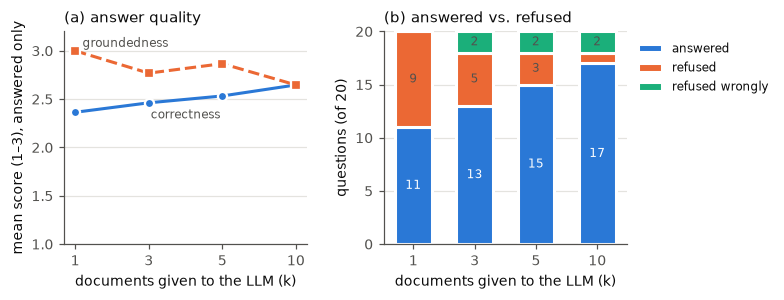

In [5]:
ks = sorted(quality, key=int)
kx = np.arange(len(ks))
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 2.8))

a.plot(kx, [quality[k]["correctness"] for k in ks], "o-", color=BLUE, markeredgecolor="white", markeredgewidth=1.5)
a.plot(kx, [quality[k]["groundedness"] for k in ks], "s--", color=ORANGE, markeredgecolor="white", markeredgewidth=1.5)
a.text(1.5, 2.3, "correctness", color=INK_2, ha="center", fontsize=8)
a.text(0.1, quality["1"]["groundedness"] + 0.04, "groundedness", color=INK_2, fontsize=8)
a.set_xticks(kx, ks)
a.set_ylim(1, 3.2)
a.set_yticks([1, 1.5, 2, 2.5, 3])
a.set_xlabel("documents given to the LLM (k)")
a.set_ylabel("mean score (1–3), answered only")
a.set_title("(a) answer quality", loc="left")

parts = [("answered", "answered", BLUE, "white"), ("refused", "refused", ORANGE, INK_2),
         ("refused_wrongly", "refused wrongly", AQUA, INK_2)]  # label ink chosen for contrast on each fill
bottom = np.zeros(len(ks))
for key, label, color, ink in parts:
    v = np.array([quality[k][key] for k in ks])
    b.bar(kx, v, 0.6, bottom=bottom, color=color, edgecolor="white", linewidth=2, label=label)
    for x, (vi, bi) in enumerate(zip(v, bottom)):
        if vi >= 2:  # a 1-question segment is too thin for a label; the axis still reads it
            b.text(x, bi + vi / 2, str(vi), ha="center", va="center", color=ink, fontsize=8)
    bottom += v
b.set_xticks(kx, ks)
b.set_ylim(0, 20)
b.set_xlabel("documents given to the LLM (k)")
b.set_ylabel("questions (of 20)")
b.set_title("(b) answered vs. refused", loc="left")
b.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
save_figure(fig, "e3_quality_vs_k",
            "Answer quality vs. k on 20 FiQA dev questions (config A, gpt-oss-120b, scored by J and H together). "
            "(a) Mean correctness and groundedness (1–3) over answered rows. (b) Answered and refused questions "
            "per k. We use k = 5. With 11–17 answered rows per k the differences are trends, not significant.")
plt.show()

In [6]:
rows = [{"k": k, "Answered / 20": quality[k]["answered"], "Correctness": f"{quality[k]['correctness']:.3f}",
         "Groundedness": f"{quality[k]['groundedness']:.3f}", "Refusal rate": f"{quality[k]['refusal_rate']:.2f}",
         "Refused wrongly": quality[k]["refused_wrongly"]} for k in ks]
print(save_table(rows, "e3_quality_k"))

| k | Answered / 20 | Correctness | Groundedness | Refusal rate | Refused wrongly |
|---|---|---|---|---|---|
| 1 | 11 | 2.364 | 3.000 | 0.45 | 0 |
| 3 | 13 | 2.462 | 2.769 | 0.35 | 2 |
| 5 | 15 | 2.533 | 2.867 | 0.25 | 2 |
| 10 | 17 | 2.647 | 2.647 | 0.15 | 2 |



## Findings (J — edit in your own words before the report)

- **The top-1 cosine is a usable refusal signal:** AUC 0.823 on the 10 verified unanswerable questions
  (only 0.558 on all 50 unverified candidates — most "removed" questions were still answered by other posts).
- **τ = 0.60 (A)** answers 76% of answerable questions and refuses 8 of 10 unanswerable ones. B needs
  **τ = 0.66** because PCA shifts the scores up; separation is unchanged (AUC 0.826).
- **More documents → more answers and higher correctness, lower groundedness:** k = 1 → 10 raises answered
  questions 11 → 17 and correctness 2.36 → 2.65, but groundedness drops 3.00 → 2.65. k = 5 is the compromise.
- **Caveats:** τ was chosen and evaluated on the same 10 questions (optimistic; 95% interval for 8/10 is about
  0.49–0.94); answer scores are one joint J+H judgement, so no inter-rater agreement.